In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Link root package modules
PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Load preprocessed feature mart
df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "features.parquet")
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df = df.sort_values(["stock_code", "transaction_date"]).reset_index(drop=True)

# 28-day out-of-time test horizon
HORIZON_DAYS = 28
cutoff_date = df["transaction_date"].max() - pd.Timedelta(days=HORIZON_DAYS)

train_df = df[df["transaction_date"] <= cutoff_date].copy()
test_df = df[df["transaction_date"] > cutoff_date].copy()

print(
    f"Train period: {train_df['transaction_date'].min().date()} →"
    f" {train_df['transaction_date'].max().date()} ({len(train_df):,} rows)"
)
print(
    f"Test period:  {test_df['transaction_date'].min().date()} →"
    f" {test_df['transaction_date'].max().date()} ({len(test_df):,} rows)"
)

Train period: 2009-12-29 → 2011-11-11 (1,336,631 rows)
Test period:  2011-11-12 → 2011-12-09 (54,796 rows)


In [2]:
def build_baseline_forecasts(full_df: pd.DataFrame, cutoff: pd.Timestamp) -> pd.DataFrame:
    eval_df = full_df[full_df["transaction_date"] > cutoff].copy()

    # 1. Flat persistence: carry forward the last observed pre-cutoff quantity
    last_known = (
        full_df[full_df["transaction_date"] <= cutoff]
        .groupby("stock_code")["total_quantity"]
        .last()
        .rename("pred_naive")
    )
    eval_df = eval_df.merge(last_known, on="stock_code", how="left")

    # 2. Seasonality & moving averages (pre-computed with leakage-safe shift(1))
    eval_df["pred_snaive_7"] = eval_df["qty_lag_7"]
    eval_df["pred_roll_7"] = eval_df["qty_rolling_mean_7"]
    eval_df["pred_roll_28"] = eval_df["qty_rolling_mean_30"]

    # Impute edge-case missing values
    preds = ["pred_naive", "pred_snaive_7", "pred_roll_7", "pred_roll_28"]
    eval_df[preds] = eval_df[preds].fillna(0)

    return eval_df

eval_df = build_baseline_forecasts(df, cutoff_date)

In [3]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    abs_err = np.abs(y_true - y_pred)
    mae = np.mean(abs_err)
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    
    # WAPE avoids division by zero on zero-demand days
    denom = np.sum(y_true)
    wape = (np.sum(abs_err) / denom) if denom > 0 else np.nan

    return {
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "WAPE (%)": round(wape * 100, 2)
    }

models = {
    "Naïve (Last Value)": "pred_naive",
    "Seasonal Naïve (Lag 7)": "pred_snaive_7",
    "Rolling Mean (7D)": "pred_roll_7",
    "Rolling Mean (28D)": "pred_roll_28",
}

y_true = eval_df["total_quantity"].values
records = []

for name, col in models.items():
    res = compute_metrics(y_true, eval_df[col].values)
    res["Model"] = name
    records.append(res)

leaderboard = pd.DataFrame(records)[["Model", "MAE", "RMSE", "WAPE (%)"]].sort_values("WAPE (%)")
display(leaderboard)

,Model,MAE,RMSE,WAPE (%)
3,Rolling Mean (28D),10.252,36.624,101.19
2,Rolling Mean (7D),10.583,37.860,104.46
1,Seasonal Naïve (Lag 7),11.337,45.466,111.91
0,Naïve (Last Value),13.311,43.964,131.39


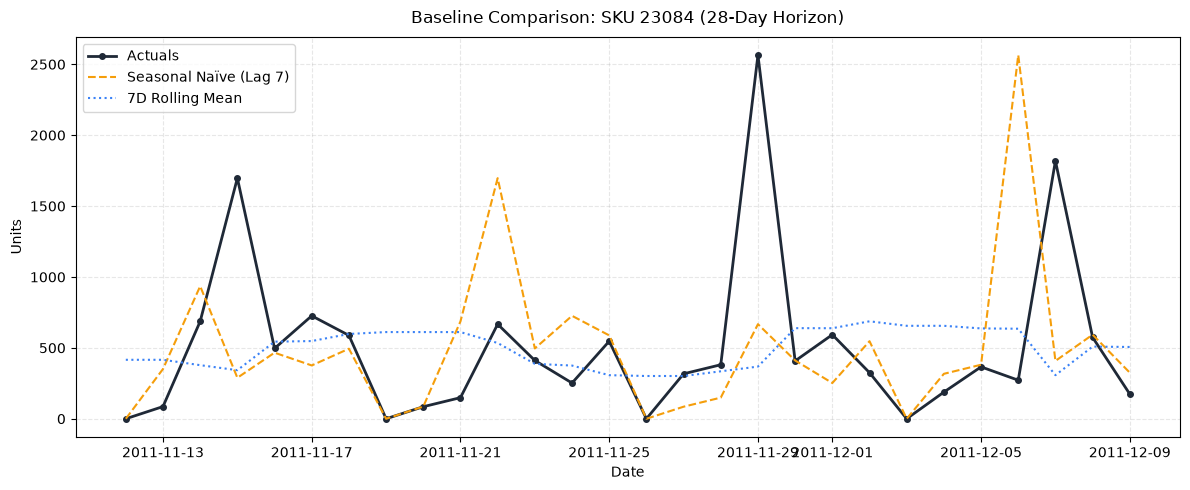

In [4]:
# Pull highest-volume SKU in test window for visual sanity check
top_sku = eval_df.groupby("stock_code")["total_quantity"].sum().idxmax()
sample = eval_df[eval_df["stock_code"] == top_sku].sort_values("transaction_date")

plt.figure(figsize=(12, 5))
plt.plot(sample["transaction_date"], sample["total_quantity"], label="Actuals", color="#1f2937", lw=2, marker="o", ms=4)
plt.plot(sample["transaction_date"], sample["pred_snaive_7"], label="Seasonal Naïve (Lag 7)", color="#f59e0b", ls="--")
plt.plot(sample["transaction_date"], sample["pred_roll_7"], label="7D Rolling Mean", color="#3b82f6", ls=":")

plt.title(f"Baseline Comparison: SKU {top_sku} (28-Day Horizon)", fontsize=12, pad=10)
plt.xlabel("Date")
plt.ylabel("Units")
plt.grid(True, alpha=0.3, ls="--")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## Experiment Notes & Benchmark Findings

### 1. Validation Setup
We evaluated all baseline models on a strict **28-day out-of-time test set** spanning from **2011-11-12 to 2011-12-09** (cutoff: `2011-11-11`). 

* **Test observations:** 54,796 product-days (1,957 unique SKUs across 28 contiguous days).
* **Total test demand:** 555,133 actual physical units sold.
* **Leakage check:** All lag and moving-average features were calculated using strict `shift(1)` offsets or historical windows anchored prior to the forecast period.

---

### 2. Baseline Leaderboard

| Model | MAE (Units) | RMSE (Units) | WAPE (%) | Total Absolute Error | Performance vs Naïve |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Rolling Mean (28-Day)** | **10.25** | **36.62** | **101.19%** | 561,759 | **-30.2% WAPE (Best Baseline)** |
| **Rolling Mean (7-Day)** | 10.58 | 37.86 | 104.46% | 579,917 | -26.9% WAPE |
| **Seasonal Naïve (Lag 7)** | 11.34 | 45.47 | 111.91% | 621,245 | -19.5% WAPE |
| **Naïve (Last Value Persistence)** | 13.31 | 43.96 | 131.39% | 729,371 | Benchmark Floor |

#### Key Takeaways
1. **The 28-day rolling average won the baseline tier:** By averaging over four weeks of sales history, it naturally dampens the volatility caused by intermittent zero-sales days. It landed at **101.19% WAPE** and an **MAE of ~10.25 units**.
2. **Weekly persistence struggled with intermittent demand:** Seasonal Naïve (Lag 7) posted a significantly higher RMSE (**45.47**). If an item sells 40 units on one Friday and 0 units the next, exact day-of-week persistence incurs an immediate 40-unit error penalty.
3. **Flat persistence completely broke down:** Projecting the single last-known sales value forward across a 4-week window generated the worst error (**131.39% WAPE**), proving that static point-in-time forecasts are useless in retail settings.

---

### 3. Catalog Demand Breakdown (Head vs Tail SKUs)

Segmenting the Seasonal Naïve results by product sales volume highlights where forecast errors actually concentrate:

* **Top 20% Volume Drivers (The Head):**
  * Accounts for **73.7% of all units sold** (409,070 units).
  * **WAPE: 101.85%** | **MAE: 37.96 units** | **RMSE: 97.49 units**
  * *Takeaway:* Head items move constantly. The large gap between MAE (38) and RMSE (97) shows that errors are driven by sudden wholesale or promotional spikes rather than zero-demand periods.

* **Bottom 80% Catalog Items (The Tail):**
  * Accounts for **26.3% of all units sold** (146,063 units).
  * **WAPE: 140.08%** | **MAE: 4.67 units** | **RMSE: 14.29 units**
  * *Takeaway:* Tail items sell only single-digit quantities when an order occurs, keeping absolute unit error low (MAE ~4.7). However, because these items go days or weeks without a single sale, heuristic baselines overshoot constantly, pushing WAPE to an unacceptable **140.08%**.

---

### 4. Target Threshold for Machine Learning Models

* **The hurdle rate:** Our subsequent gradient-boosted trees (LightGBM / XGBoost) in Notebook 05 must beat **101.19% WAPE** and an **MAE of 10.25 units** on this exact test window.
* If an ML model cannot clear that bar, it does not justify the training overhead and deployment complexity over a simple rolling database query.
* The baseline results confirm that moving averages can only smooth historical noise—they cannot capture multi-scale seasonality, price sensitivity, or sudden demand transitions. This directly justifies using tree-based machine learning for the next stage.

In [5]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Metric Calculation Engine
# ---------------------------------------------------------
def evaluate_forecast(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Calculates MAE, RMSE, and WAPE with zero-division safeguards."""
    abs_errors = np.abs(y_true - y_pred)
    mae = float(np.mean(abs_errors))
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

    total_actual = float(np.sum(y_true))
    total_abs_err = float(np.sum(abs_errors))
    wape = float((total_abs_err / total_actual) * 100) if total_actual > 0 else np.nan

    return {
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "WAPE (%)": round(wape, 2),
        "Total Actual Units": int(total_actual),
        "Total Abs Error": int(total_abs_err),
    }

# ---------------------------------------------------------
# 2. Benchmark Computation
# ---------------------------------------------------------
models = {
    "Naïve (Persistence)": "pred_naive",
    "Seasonal Naïve (Lag 7)": "pred_snaive_7",
    "Rolling Mean (7-Day)": "pred_roll_7",
    "Rolling Mean (28-Day)": "pred_roll_28",
}

y_true = eval_df["total_quantity"].values
evaluation_records = []

for model_name, pred_col in models.items():
    metrics = evaluate_forecast(y_true, eval_df[pred_col].values)
    metrics["Model"] = model_name
    evaluation_records.append(metrics)

# Format into clean leaderboard
benchmark_df = pd.DataFrame(evaluation_records)
benchmark_df = benchmark_df[
    ["Model", "MAE", "RMSE", "WAPE (%)", "Total Actual Units", "Total Abs Error"]
].sort_values("WAPE (%)").reset_index(drop=True)

# ---------------------------------------------------------
# 3. High-Volume vs Low-Volume SKU Error Breakdown
# ---------------------------------------------------------
# Segment SKUs into Top 20% (Volume Drivers) vs Bottom 80% to detect skewness
sku_volumes = eval_df.groupby("stock_code")["total_quantity"].sum()
vol_cutoff = sku_volumes.quantile(0.80)
top_skus = sku_volumes[sku_volumes >= vol_cutoff].index

eval_df["is_top_sku"] = eval_df["stock_code"].isin(top_skus)

snaive_pred = eval_df["pred_snaive_7"].values
top_mask = eval_df["is_top_sku"].values

top_metrics = evaluate_forecast(y_true[top_mask], snaive_pred[top_mask])
tail_metrics = evaluate_forecast(y_true[~top_mask], snaive_pred[~top_mask])

# ---------------------------------------------------------
# 4. Print Summary & Save Metrics to Disk
# ---------------------------------------------------------
print("=====================================================================")
print(f"BENCHMARK RESULTS: 28-DAY OUT-OF-TIME EVALUATION ({len(eval_df):,} Rows)")
print("=====================================================================")
print(benchmark_df.to_string(index=False))
print("\n---------------------------------------------------------------------")
print("SEASONAL NAÏVE (LAG 7) SEGMENTATION BREAKDOWN:")
print(f"Top 20% Volume SKUs  -> WAPE: {top_metrics['WAPE (%)']}% | MAE: {top_metrics['MAE']} | RMSE: {top_metrics['RMSE']}")
print(f"Bottom 80% Tail SKUs -> WAPE: {tail_metrics['WAPE (%)']}% | MAE: {tail_metrics['MAE']} | RMSE: {tail_metrics['RMSE']}")
print("=====================================================================")

summary_export = {
    "benchmark_leaderboard": benchmark_df.to_dict(orient="records"),
    "segmentation_snaive": {
        "top_20_percent_skus": top_metrics,
        "tail_80_percent_skus": tail_metrics,
    },
    "metadata": {
        "test_rows": int(len(eval_df)),
        "unique_skus": int(eval_df["stock_code"].nunique()),
        "horizon_days": 28,
        "cutoff_date": str(cutoff_date.date()),
    },
}

output_json_path = Path("baseline_evaluation_summary.json")
with open(output_json_path, "w", encoding="utf-8") as f:
    json.dump(summary_export, f, indent=4)

print(f"\n[INFO] Summary exported to: {output_json_path.resolve()}")

BENCHMARK RESULTS: 28-DAY OUT-OF-TIME EVALUATION (54,796 Rows)
                 Model     MAE    RMSE  WAPE (%)  Total Actual Units  Total Abs Error
 Rolling Mean (28-Day) 10.2518 36.6241    101.19              555133           561759
  Rolling Mean (7-Day) 10.5832 37.8604    104.46              555133           579917
Seasonal Naïve (Lag 7) 11.3374 45.4657    111.91              555133           621245
   Naïve (Persistence) 13.3107 43.9640    131.39              555133           729371

---------------------------------------------------------------------
SEASONAL NAÏVE (LAG 7) SEGMENTATION BREAKDOWN:
Top 20% Volume SKUs  -> WAPE: 101.85% | MAE: 37.9593 | RMSE: 97.4887
Bottom 80% Tail SKUs -> WAPE: 140.08% | MAE: 4.6692 | RMSE: 14.2947

[INFO] Summary exported to: C:\Users\lenov\OneDrive\Documents\projects\Retail-demand-Forecasting\notebooks\baseline_evaluation_summary.json
